## Standardization

**Definition:** Standardization is a feature scaling technique that transforms data so that it has a mean of 0 and a standard deviation of 1.
Also known as Z-Score Normalization


**Formula:**
$$
z = \frac{x - \mu}{\sigma}
$$

Where:
- $x$ = Original value
- $\mu$ = Mean of the feature
- $\sigma$ = Standard deviation of the feature
- $z$ = Standardized value

### Need for Standardization
1. **Equal Scale:** Brings features with different ranges to a comparable scale.
2. **Improves Model Performance:** Helps algorithms like KNN, SVM, and Logistic Regression.
3. **Prevents Dominance:** Prevents features with larger numerical values from dominating distance calculations.
4. **Faster Convergence:** Helps gradient-based algorithms like Gradient Descent converge faster.

**Note:** Standardization does not make data normally distributed; it only changes its mean and standard deviation.

In [1]:
#IMPORTING BASIC LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Loading Dataset
data=pd.read_csv(r"D:\programming\datasets\Social_Network_Ads.csv")
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [6]:
#Dividing data into categorical and numerical
data_categorical=data.drop(columns=['Age' , 'EstimatedSalary'])
data_numerical=data[['Age' , 'EstimatedSalary']]

In [7]:
X=data_numerical
y=data_categorical

## TRAIN_TEST_SPLIT ##

In [8]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test=train_test_split(X , y , test_size=0.4 , random_state=42)
X_train.mean()

Age                   37.595833
EstimatedSalary    70008.333333
dtype: float64

## STANDARDIZATION ##

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

scaler.fit(X_train)

# In a Jupyter environment, please rerun this cell to show the HTML representation or trust the notebook.
# On GitHub, the HTML representation is unable to render, please try loading this page with nbviewer.org.

StandardScaler()

In [10]:
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [ ]:
X_train_scaled #its a numpy matrix

array([[ 8.27087420e-01, -1.13039220e+00],
       [ 2.36603590e-01,  2.14107831e+00],
       [-5.86383248e-02, -2.38172967e-01],
       [-8.45950098e-01,  2.31952216e+00],
       [-5.86383248e-02, -3.86876171e-01],
       [-2.55466268e-01, -5.95060658e-01],
       [ 4.33431534e-01, -5.05838735e-01],
       [-2.55466268e-01, -9.51948350e-01],
       [ 3.35017562e-01, -1.18987348e+00],
       [ 2.36603590e-01,  5.92334433e-02],
       [-1.14119201e+00, -1.63598309e+00],
       [-6.49122155e-01, -5.97291206e-02],
       [-2.55466268e-01, -5.05838735e-01],
       [-2.55466268e-01, -1.33857668e+00],
       [-7.47536127e-01,  5.64824340e-01],
       [ 3.35017562e-01,  5.92334433e-02],
       [-9.44364070e-01,  1.57600613e+00],
       [ 8.27087420e-01,  3.56639853e-01],
       [-1.53484790e+00, -2.08432326e-01],
       [ 7.28673449e-01, -1.42779861e+00],
       [-7.47536127e-01, -6.24801299e-01],
       [-3.53880240e-01, -1.33857668e+00],
       [ 2.36603590e-01,  1.48455366e-01],
       [-5.

In [13]:
#converting numpy matrix into dataframe
X_train_scaled=pd.DataFrame(X_train_scaled,columns=data_numerical.columns)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=data_numerical.columns)

In [ ]:
X_train_scaled #Now this is a dataframe

,Age,EstimatedSalary
0,0.827087,-1.130392
1,0.236604,2.141078
2,-0.058638,-0.238173
3,-0.845950,2.319522
4,-0.058638,-0.386876
...,...,...
235,-1.338020,-1.279095
236,-1.141192,-1.041170
237,0.531846,1.873413
238,0.138190,0.207937


**DIFFERENCE BETWEEN MEAN AND STANDARD DEVIATION OF X_TRAIN BEFORE AND AFTER SCALING**

In [15]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,240.0,240.0
mean,37.6,70008.3
std,10.2,33694.3
min,18.0,15000.0
25%,30.0,44750.0
50%,37.0,69500.0
75%,45.0,87250.0
max,60.0,150000.0


In [17]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,240.0,240.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.7,-0.8
50%,-0.1,-0.0
75%,0.7,0.5
max,2.2,2.4


## GRAPHICAL REPRESENTATION AND ANALYSIS ##

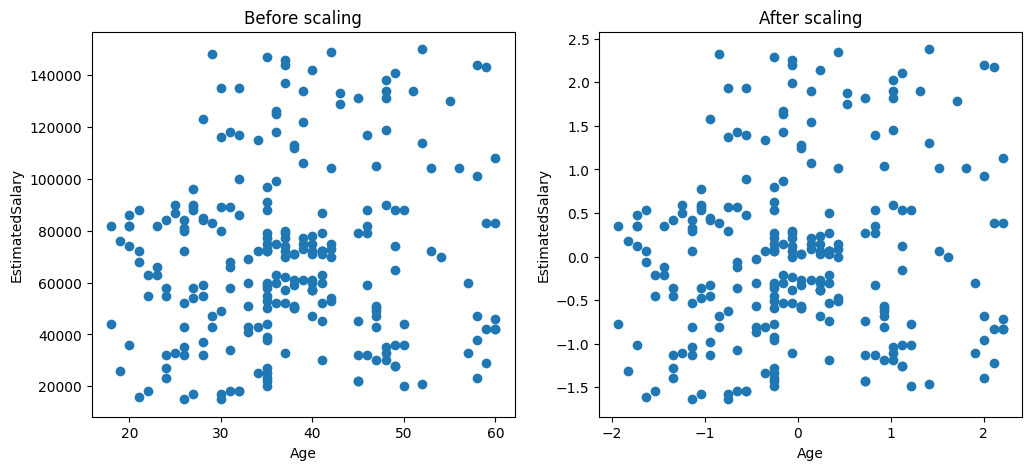

In [19]:
# Understanding the effect of standard scaling 

fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (12, 5))

#Before Scaling
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"])
ax1.set_title("Before scaling")
ax1.set_xlabel('Age')
ax1.set_ylabel('EstimatedSalary')

#After Scaling
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"])
ax2.set_title("After scaling")
ax2.set_xlabel('Age')
ax2.set_ylabel('EstimatedSalary')

plt.show()

#Data-distribution doesnt change, only values are scaled to have mean = 0 and std = 1.


C:\Users\KRISHNA GARG\AppData\Local\Temp\ipykernel_13448\819177648.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


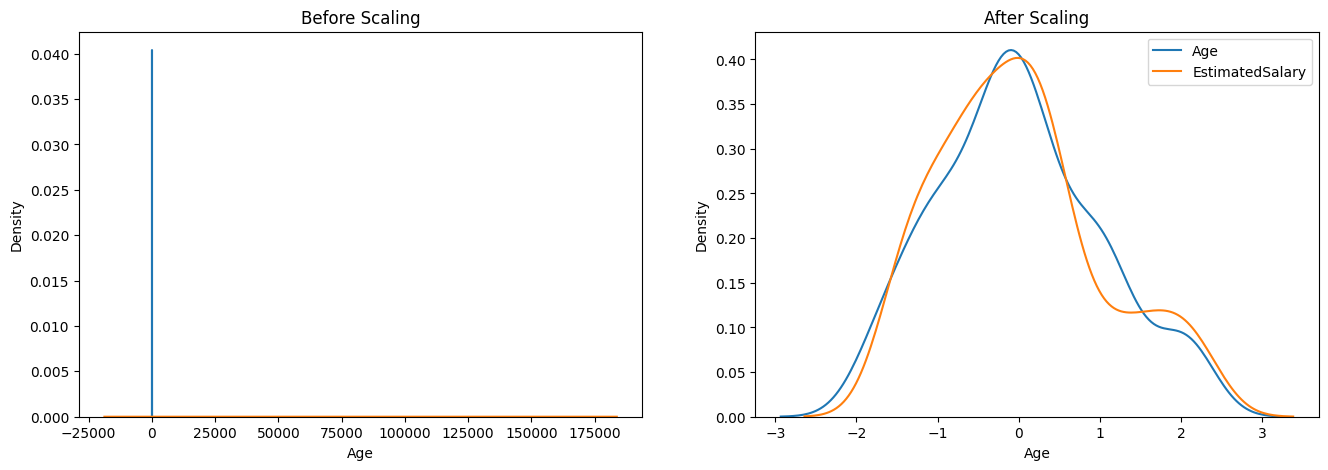

In [21]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(16, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1,label='Age')
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1,label='EstimatedSalary')
plt.legend()

# after scaling
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2,label='Age')
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2,label='EstimatedSalary')
plt.legend()
plt.show()

#It becomes easier to compare features on the same scale, which can improve the performance of machine learning algorithms.